# 04 — Paramètres de consommation et de comportement

Ce notebook calcule les totaux d'énergie, les creux, les pointes, les moyennes par période et les indicateurs de comportement. Les périodes de vacances universitaires sont lues depuis le calendrier SUP'COM placé dans `data/raw/`.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.consumption import (
    aggregate_energy_consumption,
    classify_behavior_periods,
    extract_peak_episodes,
    load_academic_breaks,
    summarize_behavior,
)

PROCESSED_PATH = PROJECT_ROOT / "data" / "processed" / "sinert_features.csv"
CALENDAR_PATH = PROJECT_ROOT / "data" / "raw" / "calendrier_complete_SUPCOM_2022-2027.xlsx"
RESULTS_DIR = PROJECT_ROOT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TIMESTAMP = "timestamp"
ENERGY = "EM_VIRTUAL kWh (kWh) [ABS]"
ACTIVE_POWER = "EM_VIRTUAL kW sys (kW) [AVG]"
APPARENT_POWER = "EM_VIRTUAL kVA sys (kVA) [AVG]"
PEAK_QUANTILE = 0.95

academic_breaks = load_academic_breaks(CALENDAR_PATH)

df = pd.read_csv(PROCESSED_PATH, parse_dates=[TIMESTAMP])
df = df.sort_values(TIMESTAMP).reset_index(drop=True)
df = classify_behavior_periods(
    df, timestamp_column=TIMESTAMP, academic_breaks=academic_breaks
)
df["hour"] = df[TIMESTAMP].dt.hour + df[TIMESTAMP].dt.minute / 60
df["date"] = df[TIMESTAMP].dt.date

print(f"Lignes analysées : {len(df):,}")
print(f"Période : {df[TIMESTAMP].min()} → {df[TIMESTAMP].max()}")
if academic_breaks:
    print(f"Périodes de vacances configurées : {len(academic_breaks)}")
else:
    print("Attention : aucune période de vacances universitaire n'est configurée.")


Lignes analysées : 127,184
Période : 2022-07-05 00:00:00 → 2026-02-28 23:45:00
Périodes de vacances configurées : 10


## 1. Totaux de consommation énergétique

Le compteur `kWh [ABS]` est cumulatif. Les totaux sont donc calculés à partir des différences entre deux relevés consécutifs de 15 minutes ; les différences qui traversent un trou temporel sont exclues.

In [2]:
aggregation_specs = {
    "journalier": "D",
    "hebdomadaire": "W-SUN",
    "mensuel": "MS",
    "annuel": "YS",
}
totals = pd.concat(
    [
        aggregate_energy_consumption(
            df,
            timestamp_column=TIMESTAMP,
            cumulative_column=ENERGY,
            period=frequency,
        ).assign(granularite=label)
        for label, frequency in aggregation_specs.items()
    ],
    ignore_index=True,
).sort_values(["granularite", TIMESTAMP])
totals = totals[["granularite", TIMESTAMP, "consumption_kwh"]]
totals.to_csv(RESULTS_DIR / "consommation_totaux.csv", index=False)
print(totals.groupby("granularite")["consumption_kwh"].agg(["count", "sum", "mean"]).round(2).to_string())


              count        sum       mean
granularite                              
annuel            5  1920919.7  384183.94
hebdomadaire    191  1920919.7   10057.17
journalier     1331  1920919.7    1443.22
mensuel          44  1920919.7   43657.27


## 2. Puissance de creux / base load

Le creux est ici la valeur minimale observée de la puissance active. Le 5e percentile est également sauvegardé comme indicateur de base load robuste aux valeurs extrêmes.

In [3]:
valid_power = df.dropna(subset=[ACTIVE_POWER, APPARENT_POWER]).copy()
min_kw_row = valid_power.loc[valid_power[ACTIVE_POWER].idxmin()]
min_kva_row = valid_power.loc[valid_power[APPARENT_POWER].idxmin()]
offpeak_parameters = pd.DataFrame(
    [
        {"parametre": "Pmin_kW", "valeur": min_kw_row[ACTIVE_POWER], "unite": "kW", "timestamp": min_kw_row[TIMESTAMP], "heure": min_kw_row[TIMESTAMP].strftime("%H:%M")},
        {"parametre": "Smin_kVA", "valeur": min_kva_row[APPARENT_POWER], "unite": "kVA", "timestamp": min_kva_row[TIMESTAMP], "heure": min_kva_row[TIMESTAMP].strftime("%H:%M")},
        {"parametre": "base_load_p05_kW", "valeur": valid_power[ACTIVE_POWER].quantile(0.05), "unite": "kW", "timestamp": pd.NaT, "heure": ""},
    ]
)
print(offpeak_parameters.to_string(index=False))


       parametre  valeur unite           timestamp heure
         Pmin_kW    6.30    kW 2023-03-25 07:15:00 07:15
        Smin_kVA    7.36   kVA 2023-03-25 07:15:00 07:15
base_load_p05_kW   21.42    kW                 NaT      


## 3. Puissance de pointe et durée des épisodes

Pmax et Smax sont les maxima observés. Pour donner une durée au pic, un épisode est défini comme une suite de points consécutifs dont la puissance active est au-dessus du 95e percentile.

In [4]:
max_kw_row = valid_power.loc[valid_power[ACTIVE_POWER].idxmax()]
max_kva_row = valid_power.loc[valid_power[APPARENT_POWER].idxmax()]
peak_episodes = extract_peak_episodes(
    df,
    timestamp_column=TIMESTAMP,
    active_power_column=ACTIVE_POWER,
    threshold_quantile=PEAK_QUANTILE,
)
peak_episodes.to_csv(RESULTS_DIR / "episodes_de_pointe.csv", index=False)

peak_parameters = pd.DataFrame(
    [
        {"parametre": "Pmax_kW", "valeur": max_kw_row[ACTIVE_POWER], "unite": "kW", "timestamp": max_kw_row[TIMESTAMP], "heure": max_kw_row[TIMESTAMP].strftime("%H:%M")},
        {"parametre": "Smax_kVA", "valeur": max_kva_row[APPARENT_POWER], "unite": "kVA", "timestamp": max_kva_row[TIMESTAMP], "heure": max_kva_row[TIMESTAMP].strftime("%H:%M")},
        {"parametre": "seuil_pic_p95_kW", "valeur": valid_power[ACTIVE_POWER].quantile(PEAK_QUANTILE), "unite": "kW", "timestamp": pd.NaT, "heure": ""},
        {"parametre": "duree_episode_max_h", "valeur": peak_episodes["duration_hours"].max(), "unite": "h", "timestamp": peak_episodes.loc[peak_episodes["duration_hours"].idxmax(), "start"], "heure": ""},
        {"parametre": "duree_totale_pointe_h", "valeur": peak_episodes["duration_hours"].sum(), "unite": "h", "timestamp": pd.NaT, "heure": ""},
        {"parametre": "nombre_episodes_pointe", "valeur": len(peak_episodes), "unite": "episodes", "timestamp": pd.NaT, "heure": ""},
    ]
)
creux_pointe = pd.concat([offpeak_parameters, peak_parameters], ignore_index=True)
creux_pointe.to_csv(RESULTS_DIR / "parametres_creux_pointe.csv", index=False)
print(peak_parameters.to_string(index=False))


             parametre  valeur    unite           timestamp heure
               Pmax_kW  290.92       kW 2024-09-02 11:45:00 11:45
              Smax_kVA  303.23      kVA 2024-09-02 11:45:00 11:45
      seuil_pic_p95_kW  129.99       kW                 NaT      
   duree_episode_max_h   57.50        h 2024-08-28 09:30:00      
 duree_totale_pointe_h 1590.50        h                 NaT      
nombre_episodes_pointe 1290.00 episodes                 NaT      


## 4. Moyennes par période et variabilité

Les statistiques sont calculées séparément pour les jours de semaine, le week-end, les saisons et les périodes universitaires configurées.

In [5]:
behavior_summaries = []
for group_column in ["day_type", "academic_period", "season"]:
    summary = summarize_behavior(
        df,
        group_column=group_column,
        active_power_column=ACTIVE_POWER,
        apparent_power_column=APPARENT_POWER,
    )
    summary.insert(0, "groupement", group_column)
    behavior_summaries.append(summary)
behavior_summary = pd.concat(behavior_summaries, ignore_index=True)
behavior_summary.to_csv(RESULTS_DIR / "moyennes_comportement.csv", index=False)
print(behavior_summary.to_string(index=False))


     groupement     day_type  EM_VIRTUAL kW sys (kW) [AVG]_mean  EM_VIRTUAL kW sys (kW) [AVG]_std  EM_VIRTUAL kW sys (kW) [AVG]_var  EM_VIRTUAL kW sys (kW) [AVG]_min  EM_VIRTUAL kW sys (kW) [AVG]_max  EM_VIRTUAL kW sys (kW) [AVG]_count  EM_VIRTUAL kVA sys (kVA) [AVG]_mean  EM_VIRTUAL kVA sys (kVA) [AVG]_std  EM_VIRTUAL kVA sys (kVA) [AVG]_var  EM_VIRTUAL kVA sys (kVA) [AVG]_min  EM_VIRTUAL kVA sys (kVA) [AVG]_max  EM_VIRTUAL kVA sys (kVA) [AVG]_count         academic_period    season
       day_type jour_semaine                          64.194915                         37.480560                       1404.792370                              6.30                            290.92                               91115                            67.651258                           38.561474                         1486.987277                                7.65                              303.23                                 91115                     NaN       NaN
       day_type      w

## 5. Heures d'activation et de désactivation

Pour obtenir une règle reproductible, le site est considéré comme en période active lorsque la puissance horaire moyenne dépasse la moyenne globale de puissance active. On retient la première et la dernière heure de cette fenêtre typique, puis on décline le calcul par type de jour et par saison.

In [6]:
activation_threshold_kw = valid_power[ACTIVE_POWER].mean()
df["hour_int"] = df[TIMESTAMP].dt.hour
hourly_profile = df.groupby("hour_int")[ACTIVE_POWER].mean()
active_profile_hours = hourly_profile[hourly_profile >= activation_threshold_kw]
typical_activation_hour = float(active_profile_hours.index.min())
typical_desactivation_hour = float(active_profile_hours.index.max())
typical_duration_hours = typical_desactivation_hour - typical_activation_hour + 1

activation_windows = []
for group_column in ["day_type", "academic_period", "season"]:
    for group_value, group in df.groupby(group_column):
        profile = group.groupby("hour_int")[ACTIVE_POWER].mean()
        active_hours = profile[profile >= activation_threshold_kw]
        activation_windows.append(
            {
                "groupement": group_column,
                "groupe": group_value,
                "activation_hour": active_hours.index.min() if not active_hours.empty else pd.NA,
                "desactivation_hour": active_hours.index.max() if not active_hours.empty else pd.NA,
                "duree_typique_heures": len(active_hours),
            }
        )
activation_windows = pd.DataFrame(activation_windows)
activation_windows.to_csv(RESULTS_DIR / "fenetres_activation_groupes.csv", index=False)

global_variability = {
    "activation_threshold_kw": activation_threshold_kw,
    "activation_hour_typique": typical_activation_hour,
    "desactivation_hour_typique": typical_desactivation_hour,
    "duree_typique_heures": typical_duration_hours,
    "active_power_mean_kw": valid_power[ACTIVE_POWER].mean(),
    "active_power_std_kw": valid_power[ACTIVE_POWER].std(),
    "active_power_variance_kw2": valid_power[ACTIVE_POWER].var(),
    "active_power_coefficient_variation": valid_power[ACTIVE_POWER].std() / valid_power[ACTIVE_POWER].mean(),
}
with (RESULTS_DIR / "parametres_comportement.json").open("w", encoding="utf-8") as output_file:
    json.dump(global_variability, output_file, indent=2, ensure_ascii=False, default=str)
print(pd.Series(global_variability).round(4).to_string())


activation_threshold_kw                 60.4473
activation_hour_typique                  8.0000
desactivation_hour_typique              17.0000
duree_typique_heures                    10.0000
active_power_mean_kw                    60.4473
active_power_std_kw                     36.1833
active_power_variance_kw2             1309.2298
active_power_coefficient_variation       0.5986

## 6. Graphiques de synthèse

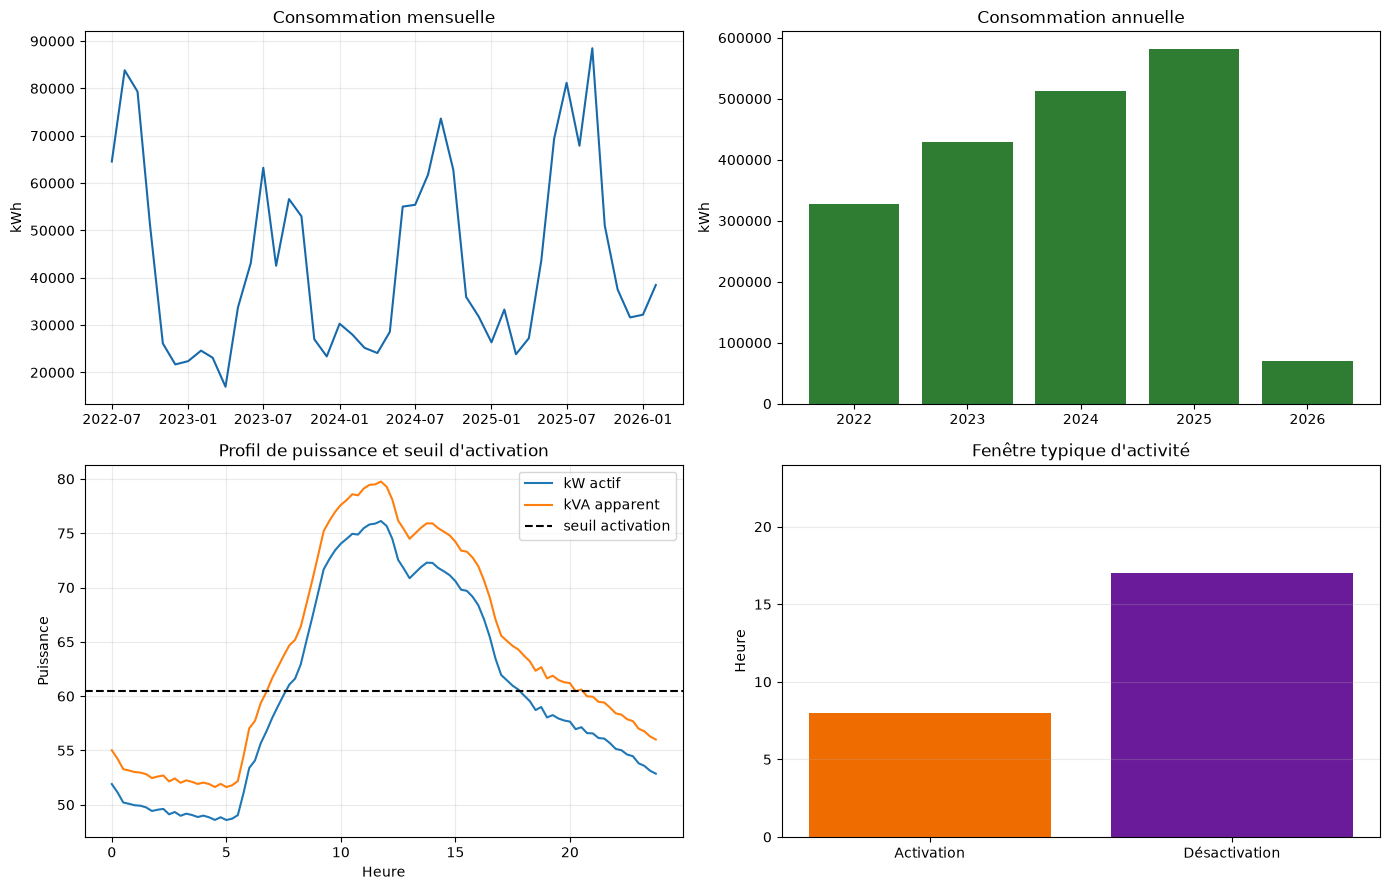

In [7]:
monthly = totals.loc[totals["granularite"] == "mensuel"].copy()
annual = totals.loc[totals["granularite"] == "annuel"].copy()
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(monthly[TIMESTAMP], monthly["consumption_kwh"], color="#1769aa")
axes[0, 0].set_title("Consommation mensuelle")
axes[0, 0].set_ylabel("kWh")
axes[0, 0].grid(alpha=0.25)

axes[0, 1].bar(annual[TIMESTAMP].dt.year.astype(str), annual["consumption_kwh"], color="#2e7d32")
axes[0, 1].set_title("Consommation annuelle")
axes[0, 1].set_ylabel("kWh")

hourly = df.groupby("hour")[[ACTIVE_POWER, APPARENT_POWER]].mean()
axes[1, 0].plot(hourly.index, hourly[ACTIVE_POWER], label="kW actif")
axes[1, 0].plot(hourly.index, hourly[APPARENT_POWER], label="kVA apparent")
axes[1, 0].axhline(activation_threshold_kw, color="black", linestyle="--", label="seuil activation")
axes[1, 0].set_title("Profil de puissance et seuil d'activation")
axes[1, 0].set_xlabel("Heure")
axes[1, 0].set_ylabel("Puissance")
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.25)

axes[1, 1].bar(["Activation", "Désactivation"], [typical_activation_hour, typical_desactivation_hour], color=["#ef6c00", "#6a1b9a"])
axes[1, 1].set_title("Fenêtre typique d'activité")
axes[1, 1].set_ylabel("Heure")
axes[1, 1].set_ylim(0, 24)
axes[1, 1].grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(RESULTS_DIR / "06_parametres_consommation_comportement.png", dpi=150)
plt.show()
plt.close(fig)
